# Ajuste de LightGBM y mejora de BiLSTM

Comparación sobre **62 sujetos de desarrollo**, 122 registros y 152.052 objetivos de cinco clases. Cinco folds externos fijos por sujeto; 16 sujetos de test reservados.

Métrica primaria: **F1 macro promedio entre folds**. Secundarias: accuracy, kappa y métricas por estadio/sujeto. Se ajustan hiperparámetros, no calibradores de probabilidades. Las referencias son LightGBM 0,7822 y BiLSTM 0,7687 de las campañas previas.

`RUN_TRAINING=False` revisa artefactos guardados. La selección de familias entre campañas es exploratoria; los resultados OOF no sustituyen el test final.

In [1]:
from pathlib import Path
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "0")
import json
import sys
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
import torch
from sleep_staging.config import CLASSES
from sleep_staging.evaluation import evaluate
from sleep_staging.provenance import hash_file
from sleep_staging.research import paired_subject_bootstrap
from sleep_staging.refinement import run_family, compare_families

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists(): ROOT = ROOT.parent
OUTPUT = ROOT / "var/research/sc-w30-refinement-v1"
REFERENCE = ROOT / "var/research/sc-w30-v2/campaign.json"
NEURAL_REFERENCE = ROOT / "var/research/sc-w30-lstm-mps-v1/campaign.json"
CONFIG = ROOT / "configs/research/refinement.yaml"
RUN_TRAINING = False
PRIMARY_METRIC = "f1_macro"
SECONDARY_METRICS = ["accuracy", "kappa"]
CLASSES_5 = CLASSES["task_5"]
assert "lightgbm" not in sys.modules, "Mantener LightGBM en el worker CPU aislado."
print({"torch": version("torch"), "lightgbm": version("lightgbm"), "mps_available": torch.backends.mps.is_available(), "fallback": os.environ.get("PYTORCH_ENABLE_MPS_FALLBACK")})


/Users/adrianalarcon/.paradev/projects/maia_proyecto/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'torch': '2.14.1', 'lightgbm': '4.7.0', 'mps_available': True, 'fallback': '0'}


## Diseño y protocolo

LightGBM compara doce configuraciones de hojas, learning rate, máximo de iteraciones, muestras por hoja, bins, regularización, muestreo y pesos de clase. Su early stopping utiliza únicamente F1 macro interno sin ponderar.

BiLSTM compara seis configuraciones: representación de 145/435 variables, normalización por registro, capacidad, dropout, learning rate y pesos de clase. Las ventanas son centradas de 15 segmentos. Las 435 variables ya incluyen contexto suavizado: encadenarlas con ventanas de la red amplía el contexto efectivo.

Cada entrenamiento externo reserva el 20 % de sus sujetos para selección interna. Se eligen configuración y número de iteraciones o épocas, se reentrena desde cero sobre todo el entrenamiento externo y se predice su fold al terminar. No se usa early stopping externo.

La normalización por noche no usa etiquetas ni otros registros; utiliza la noche completa y es retrospectiva. El recorte de vigilia sigue dependiendo de anotaciones. Se comparan soluciones completas sobre los mismos objetivos, con entradas y normalización diferentes.

In [2]:
if RUN_TRAINING:
    for family in ["lgbm", "bilstm"]:
        run_family(CONFIG, REFERENCE, OUTPUT, family)
    comparison = compare_families(OUTPUT, REFERENCE, NEURAL_REFERENCE)
else:
    if not (OUTPUT / "comparison.json").exists():
        raise FileNotFoundError("Completar ambas familias y ejecutar scripts/run_refinement.py --mode compare.")
    comparison = json.loads((OUTPUT / "comparison.json").read_text())
assert comparison["test_evaluated"] is False
families = comparison["families"]
reference = json.loads(REFERENCE.read_text())
old_neural = json.loads(NEURAL_REFERENCE.read_text())
old_best = next(r for r in old_neural["neural_results"] if r["name"] == old_neural["best_neural"])
raw = pd.read_parquet(reference["dataset"])
frame = raw.loc[raw.task_5.notna()]
splits = pd.read_csv(ROOT / "configs/splits/sc_subjects_v1.csv")
assert not set(frame.subject_id) & set(splits.loc[splits.partition.eq("test"), "subject_id"])
assert frame.groupby("subject_id").fold.nunique().max() == 1
assert families["lgbm"]["provenance"] == families["bilstm"]["provenance"]
assert hash_file(Path(reference["dataset"])) == families["lgbm"]["provenance"]["dataset_sha256"]
print({"subjects": frame.subject_id.nunique(), "recordings": frame.recording_id.nunique(), "targets": len(frame), "test_evaluated": comparison["test_evaluated"]})
display(frame.groupby("fold").agg(subjects=("subject_id", "nunique"), epochs=("epoch_id", "count")))
print("LightGBM: CPU aislada; BiLSTM: MPS float32 sin fallback.")


{'subjects': 62, 'recordings': 122, 'targets': 152052, 'test_evaluated': False}


,subjects,epochs
fold,,
0,13,29788
1,13,33150
2,12,33483
3,12,28353
4,12,27278


LightGBM: CPU aislada; BiLSTM: MPS float32 sin fallback.


## Espacios reales de búsqueda y auditoría

Los espacios se congelaron antes de evaluar folds externos. Se muestran los valores completos de configuración, incluidos defaults. `weight_power=1` usa pesos inversos; `0,5` su raíz cuadrada; `0` produce pesos iguales.

`raw145`: variables originales ampliadas. `night145`: las mismas normalizadas por registro. `context435`: vista del campeón, con 145 variables y 290 resúmenes temporales (pasado de cuatro y centro de 15 segmentos), ya normalizados dentro de cada noche. `night435`: normalización adicional por registro del conjunto completo de 435 variables. Por tanto, `context435` también requiere estadísticas de la noche completa. El escalado posterior se ajusta solo en entrenamiento.

LightGBM se entrena y predice en workers sin Torch para evitar el conflicto nativo OpenMP observado en macOS. El proceso MPS no importa LightGBM.

In [3]:
config = families["lgbm"]["config"]
display(pd.DataFrame(config["lgbm"]))
display(pd.DataFrame(config["bilstm"]))
audit = []
for family, result in families.items():
    assert len(result["folds"]) == 5
    for fold in result["folds"]:
        a, b, c = map(set, [fold["training_subjects"], fold["validation_subjects"], fold["external_subjects"]])
        assert not a & b and not (a | b) & c
        assert len(a | b | c) == 62
        selected = fold["selected"]
        audit.append({"family": family, "fold": fold["fold"], "selected": selected["configuration"]["name"], "trees_or_epochs": selected["best_epoch"], "inner_f1": selected["best_f1_macro"], "outer_f1": fold["metrics"]["f1_macro"]})
display(pd.DataFrame(audit))
print("CV inner fits:", sum(len(f["trials"]) for r in families.values() for f in r["folds"]))
print("External refits:", len(audit))

# Detectar candidatos cuyo entrenamiento agotó el presupuesto antes de completar paciencia.
capped = []
for family, result in families.items():
    for phase in [*result["folds"], result["candidate"]]:
        for trial in phase["trials"]:
            if family == "lgbm":
                history = json.loads((Path(trial["directory"]) / "history.json").read_text())["valid_0"]["macro_f1"]
                completed = len(history)
                maximum = trial["configuration"]["n_estimators"]
            else:
                completed = trial["epochs_completed"]
                maximum = result["config"]["nn_max_epochs"]
            if completed == maximum:
                capped.append({"family": family, "phase": phase.get("fold", "final"), "candidate": trial["configuration"]["name"], "selected_iteration": trial["best_epoch"], "completed_iterations": completed})
capped = pd.DataFrame(capped, columns=["family", "phase", "candidate", "selected_iteration", "completed_iterations"])
capped.to_csv(OUTPUT / "capped-trials.csv", index=False)
print("Ensayos que agotaron su presupuesto; no prueban convergencia:")
display(capped)


,name,n_estimators,learning_rate,num_leaves,min_child_samples,max_bin,reg_alpha,reg_lambda,colsample_bytree,subsample,subsample_freq,weight_power
0,reference,300,0.05,15,20,255,0.0,0.0,1.0,1.0,0,1.0
1,compact_regularized,450,0.05,15,100,63,0.0,3.0,0.8,0.8,1,1.0
2,medium_regularized,450,0.05,31,100,63,0.0,3.0,0.8,0.8,1,1.0
3,medium_slow,450,0.03,31,100,63,0.0,5.0,0.8,0.8,1,1.0
4,medium_fast,450,0.08,31,100,63,0.0,3.0,0.8,0.8,1,1.0
5,large_regularized,450,0.05,63,200,63,0.0,5.0,0.8,0.8,1,1.0
6,conservative,450,0.05,31,500,63,0.0,10.0,0.8,0.8,1,1.0
7,compact_half_weights,450,0.05,15,100,63,0.0,3.0,0.8,0.8,1,0.5
8,medium_half_weights,450,0.05,31,100,63,0.0,3.0,0.8,0.8,1,0.5
9,large_half_weights,450,0.05,63,200,63,0.0,5.0,0.8,0.8,1,0.5


,name,view,hidden_size,dropout,weight_power,lr
0,reference145,raw145,64,0.3,1.0,0.0003
1,night145_moderate,night145,64,0.4,0.5,0.0003
2,context435_moderate,context435,64,0.4,0.5,0.0003
3,night435_moderate,night435,64,0.4,0.5,0.0003
4,night435_larger,night435,128,0.5,0.5,0.0003
5,night435_unweighted,night435,64,0.4,0.0,0.0010


,family,fold,selected,trees_or_epochs,inner_f1,outer_f1
0,lgbm,0,large_regularized,129,0.788417,0.754582
1,lgbm,1,large_regularized,280,0.773135,0.797610
2,lgbm,2,large_regularized,287,0.757798,0.799243
3,lgbm,3,large_regularized,409,0.793067,0.804181
4,lgbm,4,large_half_weights,118,0.817542,0.790647
5,bilstm,0,context435_moderate,5,0.794742,0.747697
6,bilstm,1,context435_moderate,3,0.760052,0.795598
7,bilstm,2,context435_moderate,1,0.748203,0.788307
8,bilstm,3,context435_moderate,9,0.787133,0.782731
9,bilstm,4,context435_moderate,7,0.815032,0.785746


CV inner fits: 90
External refits: 10
Ensayos que agotaron su presupuesto; no prueban convergencia:


,family,phase,candidate,selected_iteration,completed_iterations
0,lgbm,0,reference,281,300
1,lgbm,1,reference,267,300
2,lgbm,1,compact_regularized,449,450
3,lgbm,1,medium_slow,439,450
4,lgbm,3,reference,299,300
5,lgbm,3,medium_regularized,424,450
6,lgbm,3,medium_slow,446,450
7,lgbm,3,sparse_regularized,449,450
8,lgbm,4,compact_regularized,436,450
9,lgbm,4,medium_slow,412,450


## Selección interna y curvas

Diagnóstico del primer fold de cada familia. Se muestran los tres mejores candidatos internos LightGBM, la puntuación interna de los doce, pérdidas de los dos mejores candidatos neuronales y F1 interno de los seis. Son datos internos de selección, no resultados externos.

El número de iteraciones del mejor checkpoint y el total de iteraciones ejecutadas son distintos. La tabla anterior identifica límites de presupuesto; una selección cercana al máximo aconseja ampliar esa búsqueda interna en otra campaña.

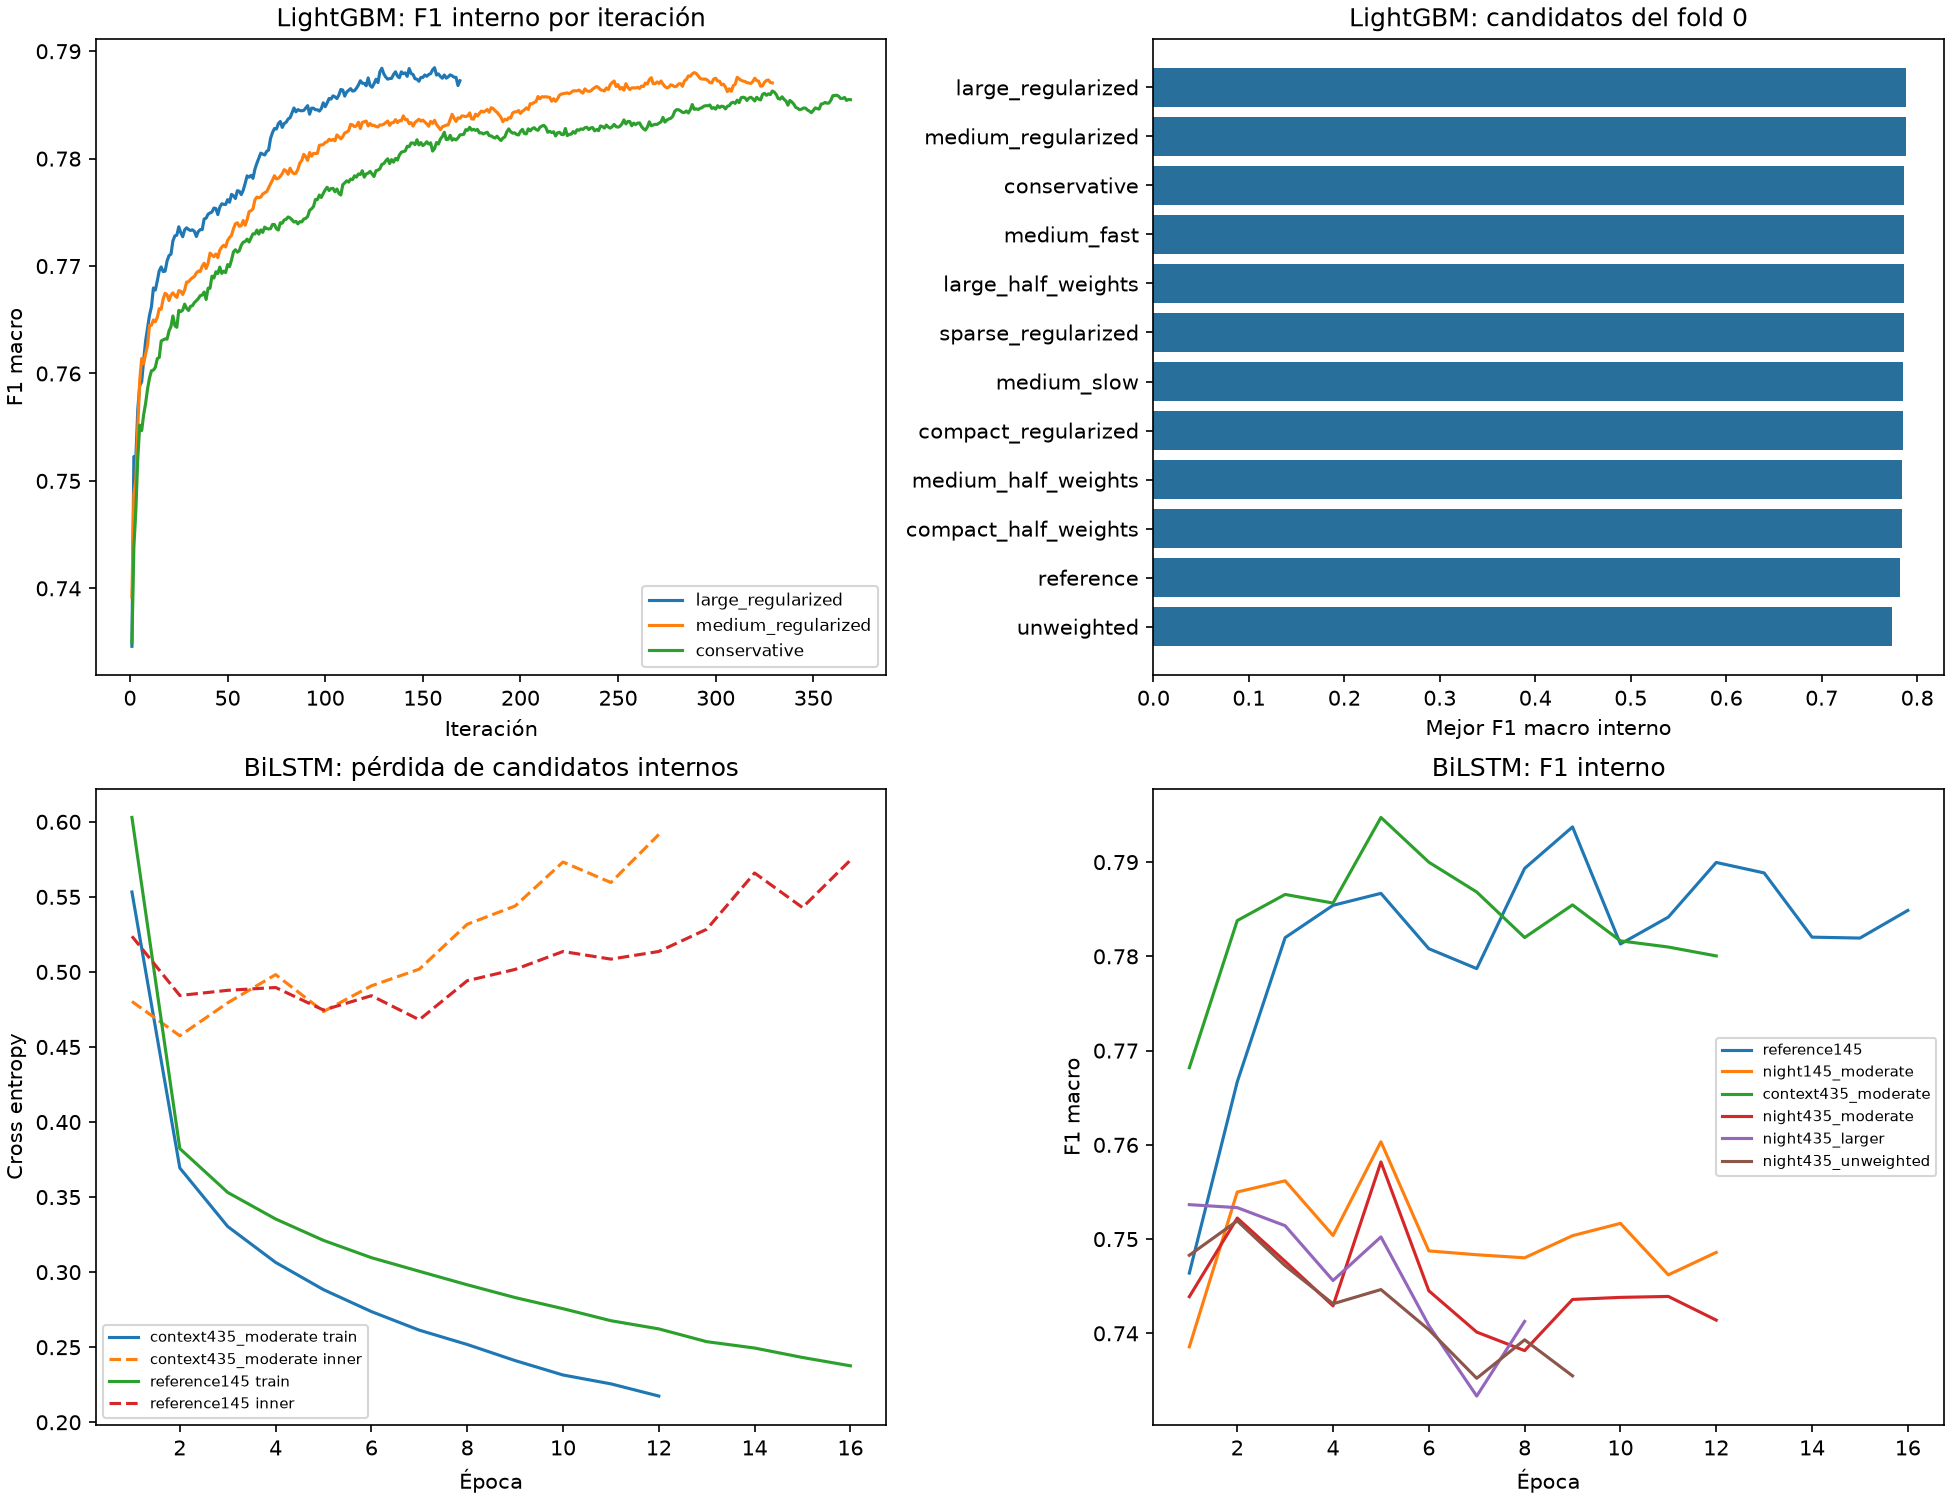

In [4]:
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(exist_ok=True)
fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
trials = families["lgbm"]["folds"][0]["trials"]
for trial in sorted(trials, key=lambda r: r["best_f1_macro"], reverse=True)[:3]:
    h = json.loads((Path(trial["directory"]) / "history.json").read_text())["valid_0"]["macro_f1"]
    axes[0, 0].plot(np.arange(1, len(h)+1), h, label=trial["configuration"]["name"])
axes[0, 0].set(title="LightGBM: F1 interno por iteración", xlabel="Iteración", ylabel="F1 macro")
axes[0, 0].legend(fontsize=8)
ordered = sorted(trials, key=lambda r: r["best_f1_macro"])
axes[0, 1].barh([t["configuration"]["name"] for t in ordered], [t["best_f1_macro"] for t in ordered], color="#286F9B")
axes[0, 1].set(title="LightGBM: candidatos del fold 0", xlabel="Mejor F1 macro interno")
trials = families["bilstm"]["folds"][0]["trials"]
for trial in sorted(trials, key=lambda r: r["best_f1_macro"], reverse=True)[:2]:
    h = pd.read_json(Path(trial["directory"]) / "history.json")
    label = trial["configuration"]["name"]
    axes[1, 0].plot(h.epoch, h.train_loss, label=label + " train")
    axes[1, 0].plot(h.epoch, h.inner_loss, linestyle="--", label=label + " inner")
for trial in trials:
    h = pd.read_json(Path(trial["directory"]) / "history.json")
    axes[1, 1].plot(h.epoch, h.inner_f1_macro, label=trial["configuration"]["name"])
axes[1, 0].set(title="BiLSTM: pérdida de candidatos internos", xlabel="Época", ylabel="Cross entropy")
axes[1, 1].set(title="BiLSTM: F1 interno", xlabel="Época", ylabel="F1 macro")
axes[1, 0].legend(fontsize=7)
axes[1, 1].legend(fontsize=7)
path = FIGURES / "tuning-curves.png"
fig.savefig(path, dpi=150)
display(Image(filename=str(path)))
plt.close(fig)


## Comparación completa y ganador

F1 macro, accuracy y kappa son promedios entre cinco folds. La desviación entre folds no es un intervalo de confianza. Las referencias usan predicciones congeladas de las campañas anteriores y exactamente las mismas claves de desarrollo.

En LightGBM, los valores de `n_estimators` y `best_epoch` del contrato compartido cuentan iteraciones de boosting; con cinco clases se ajustan cinco árboles por iteración.

,name,f1_macro,f1_std,accuracy,kappa
0,lgbm_tuned,0.7893,0.0179,0.8300,0.7691
1,lightgbm_original,0.7822,0.0161,0.8167,0.7539
2,bilstm_tuned,0.7800,0.0167,0.8187,0.7551
3,bilstm_original,0.7687,0.0211,0.8007,0.7351


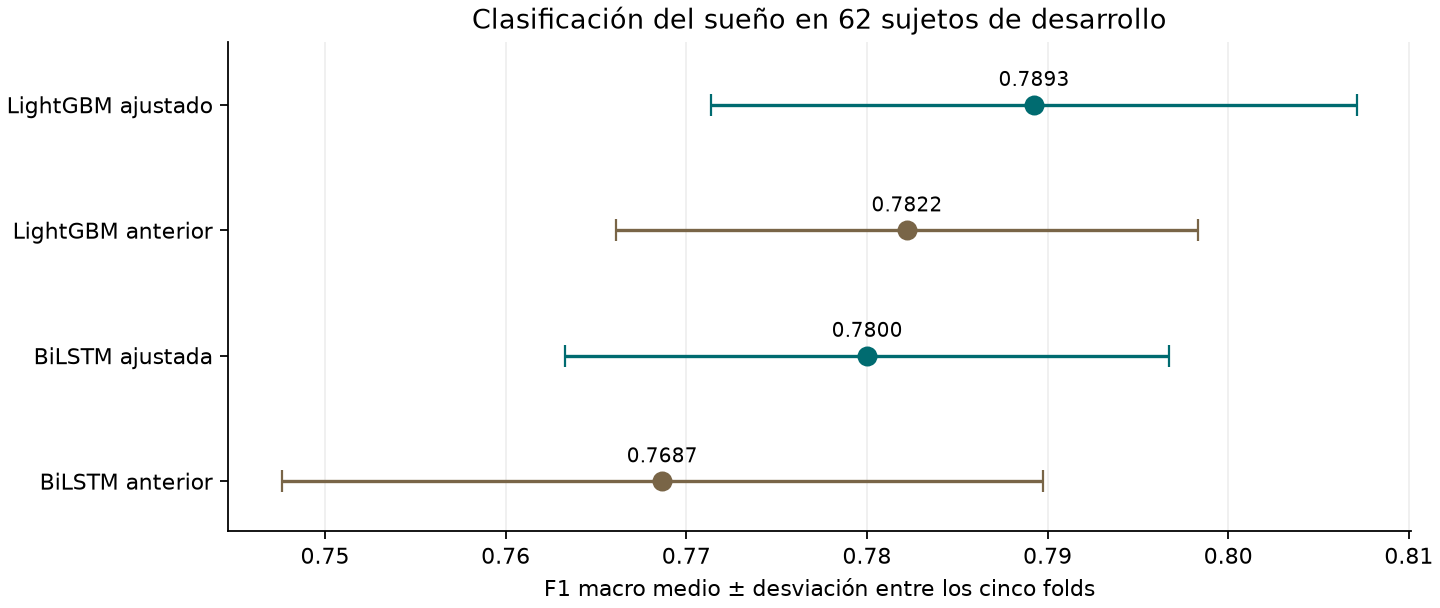

In [5]:
board = pd.DataFrame(comparison["leaderboard"]).sort_values("f1_macro", ascending=False)
display(board.round(4))
names = {"lightgbm_original": "LightGBM anterior", "bilstm_original": "BiLSTM anterior", "lgbm_tuned": "LightGBM ajustado", "bilstm_tuned": "BiLSTM ajustada"}
fig, ax = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
ordered = board.sort_values("f1_macro")
for i, r in enumerate(ordered.itertuples()):
    ax.errorbar(r.f1_macro, i, xerr=r.f1_std, fmt="o", color="#006b70" if r.name.endswith("tuned") else "#796547", capsize=5, markersize=8)
    ax.text(r.f1_macro, i+0.15, f"{r.f1_macro:.4f}", ha="center", fontsize=9)
ax.set_yticks(range(len(ordered)), [names[name] for name in ordered.name])
ax.set(ylim=(-0.4, len(ordered)-0.5), xlabel="F1 macro medio ± desviación entre los cinco folds", title="Clasificación del sueño en 62 sujetos de desarrollo")
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
path = FIGURES / "model-comparison.png"
fig.savefig(path, dpi=160)
display(Image(filename=str(path)))
plt.close(fig)


## Estadios, sujetos e incertidumbre

Se recalculan métricas OOF y se distinguen del promedio de folds. El bootstrap emparejado remuestrea sujetos completos con sus noches: sus intervalos son condicionales a los modelos OOF ajustados y no cubren toda la variabilidad del entrenamiento ni el test final.

In [6]:
ref_oof = pd.read_parquet(Path(reference["winner"]["run_dir"]) / "oof.parquet")
old_nn_oof = pd.read_parquet(Path(old_best["directory"]) / "oof.parquet")
reports = []
subjects = []
all_oof = {"lightgbm_original": ref_oof, "bilstm_original": old_nn_oof}
for family, result in families.items():
    path = Path(result["directory"]) / "oof.parquet"
    assert hash_file(path) == result["oof_sha256"]
    all_oof[family + "_tuned"] = pd.read_parquet(path)
for name, table in all_oof.items():
    assert len(table) == len(frame) and not table.epoch_id.duplicated().any()
    assert set(table.epoch_id) == set(frame.epoch_id)
    m = evaluate(table.y_true.to_numpy(), table.y_pred.to_numpy(), CLASSES_5)
    report = pd.DataFrame(m["report"]).T.reindex(CLASSES_5)[["precision", "recall", "f1-score", "support"]]
    report["model"] = name
    reports.append(report.reset_index(names="stage"))
    for subject, group in table.groupby("subject_id", sort=True):
        s = evaluate(group.y_true.to_numpy(), group.y_pred.to_numpy(), CLASSES_5)
        subjects.append({"model": name, "subject_id": subject, **{k:s[k] for k in ["f1_macro", "accuracy", "kappa"]}})
display(pd.concat(reports).pivot(index="stage", columns="model", values="f1-score").reindex(CLASSES_5))
subject_metrics = pd.DataFrame(subjects)
subject_metrics.to_csv(OUTPUT / "subject-metrics.csv", index=False)
display(subject_metrics.groupby("model")[["f1_macro", "accuracy", "kappa"]].agg(["mean", "median", "std"]))
bootstrap = {family + "_vs_lightgbm_original": r["paired_bootstrap"] for family, r in families.items()}
additional = paired_subject_bootstrap(old_nn_oof, all_oof["bilstm_tuned"])
additional.update(reference="bilstm_original", candidate="bilstm_tuned")
bootstrap["bilstm_vs_previous_neural"] = additional
(OUTPUT / "additional-bootstrap.json").write_text(json.dumps(bootstrap, indent=2))
display(pd.DataFrame(bootstrap).T[["delta", "ci95", "subjects", "scope"]])


model,bilstm_original,bilstm_tuned,lgbm_tuned,lightgbm_original
stage,,,,
W,0.921372,0.923080,0.924045,0.918096
N1,0.518982,0.512623,0.515889,0.523416
N2,0.804221,0.831728,0.848711,0.829410
N3,0.765647,0.790828,0.808447,0.791486
REM,0.836394,0.848301,0.854034,0.852774


f1_macro                      accuracy                      \
                       mean    median       std      mean    median       std   
model                                                                           
bilstm_original    0.720876  0.745830  0.098059  0.797987  0.807982  0.072309   
bilstm_tuned       0.727585  0.745850  0.089905  0.816989  0.821096  0.063483   
lgbm_tuned         0.743757  0.762921  0.078902  0.828845  0.831023  0.054864   
lightgbm_original  0.736399  0.750305  0.078936  0.814536  0.817796  0.056971   

                      kappa                      
                       mean    median       std  
model                                            
bilstm_original    0.720217  0.732936  0.097749  
bilstm_tuned       0.742397  0.756179  0.085479  
lgbm_tuned         0.758297  0.768180  0.076154  
lightgbm_original  0.741689  0.752037  0.077500

,delta,ci95,subjects,scope
lgbm_vs_lightgbm_original,0.007189,"[0.0031426294031420164, 0.01121171709573157]",62,conditional_on_fitted_oof_models_not_final_test
bilstm_vs_lightgbm_original,-0.001724,"[-0.00921672968297176, 0.005646732156405827]",62,conditional_on_fitted_oof_models_not_final_test
bilstm_vs_previous_neural,0.011989,"[0.001882613424338947, 0.02250011744616031]",62,conditional_on_fitted_oof_models_not_final_test


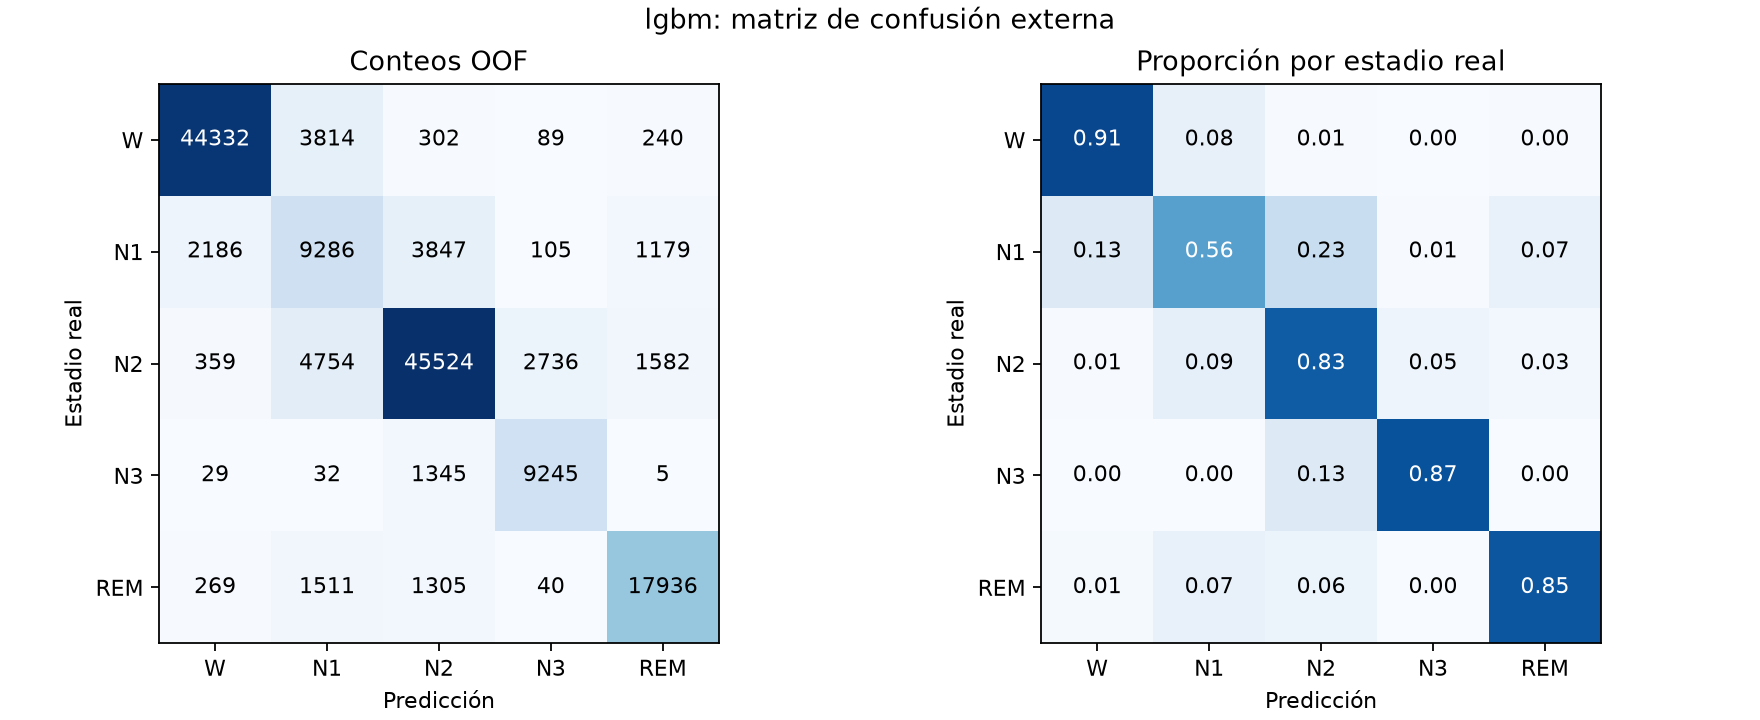

In [7]:
best_new = max(families, key=lambda name: families[name]["f1_macro"])
table = all_oof[best_new + "_tuned"]
m = evaluate(table.y_true.to_numpy(), table.y_pred.to_numpy(), CLASSES_5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
fig.suptitle(f"{best_new}: matriz de confusión externa")
for ax, key, title in zip(axes, ["confusion", "confusion_normalized"], ["Conteos OOF", "Proporción por estadio real"]):
    values = np.asarray(m[key]); maximum = 1 if key.endswith("normalized") else values.max()
    ax.imshow(values, cmap="Blues", vmin=0, vmax=maximum)
    ax.set_xticks(range(5), CLASSES_5); ax.set_yticks(range(5), CLASSES_5)
    ax.set(xlabel="Predicción", ylabel="Estadio real", title=title)
    for (i,j), value in np.ndenumerate(values):
        ax.text(j,i,f"{value:.2f}" if key.endswith("normalized") else str(int(value)),ha="center",va="center",color="white" if value > maximum*0.5 else "black")
path = FIGURES / "best-new-confusion.png"
fig.savefig(path, dpi=160)
display(Image(filename=str(path)))
plt.close(fig)


## Candidatos finales, MLflow y conclusión

Después de CV se repite la selección interna sobre desarrollo para cada familia y se ajusta su candidato con los 62 sujetos. Las configuraciones finales pueden diferir de las elegidas en cada fold.

El pipeline LightGBM se guarda como joblib y se recarga en el worker CPU. La BiLSTM conserva arquitectura, escalador, columnas y contrato de ventanas; la vista de entrada se reconstruye según la configuración elegida. El alias histórico se conserva.

[MLflow local](http://127.0.0.1:5002): experimento `sleep-cassette-lgbm-bilstm-refinement-v1`. Checkpoints, parámetros, curvas y auditorías permanecen en los artefactos de sus runs.

In [8]:
for family, result in families.items():
    candidate = result["candidate"]
    assert candidate["reload_equal"] and candidate["probabilities_sum_to_one"]
    print(family, "configuración elegida para el ajuste final:")
    display(pd.Series(candidate["selected"]["configuration"]))
    print("Iteraciones de boosting o épocas:", candidate["selected"]["best_epoch"])
    checkpoint = Path(candidate["refit"]["directory"]) / ("model.joblib" if family == "lgbm" else "model.pt")
    assert hash_file(checkpoint) == candidate["refit"]["model_sha256"]
    print("Candidate run:", candidate["mlflow_run_id"])
print("Mayor F1 de desarrollo:", comparison["winner"])
print("Primary metric:", board.iloc[0]["f1_macro"])
print("Secondary metrics:", board.iloc[0][["accuracy", "kappa"]].to_dict())
print("Desviación entre folds:", board.iloc[0]["f1_std"])
print("Key features: per-epoch multichannel descriptors and retrospective context")
print("Notebook: notebook/06_lgbm_bilstm_tuning.ipynb")
print("Next iteration: confirmar estabilidad y sensibilidad al recorte antes de congelar el modelo y evaluar el test final.")
print("Test evaluated:", comparison["test_evaluated"])


lgbm configuración elegida para el ajuste final:


name                 large_regularized
n_estimators                       450
learning_rate                     0.05
num_leaves                          63
min_child_samples                  200
max_bin                             63
reg_alpha                            0
reg_lambda                         5.0
colsample_bytree                   0.8
subsample                          0.8
subsample_freq                       1
weight_power                         1
dtype: object

Iteraciones de boosting o épocas: 261
Candidate run: 99f262e3d8de463a841791d7831c0f91
bilstm configuración elegida para el ajuste final:


name            reference145
view                  raw145
hidden_size               64
dropout                  0.3
weight_power             1.0
lr                    0.0003
dtype: object

Iteraciones de boosting o épocas: 6
Candidate run: 100572d188ec42dca85a8fdf5af01278
Mayor F1 de desarrollo: lgbm_tuned
Primary metric: 0.7892523860901687
Secondary metrics: {'accuracy': 0.8300026083794918, 'kappa': 0.769057376816154}
Desviación entre folds: 0.0178691587695785
Key features: per-epoch multichannel descriptors and retrospective context
Notebook: notebook/06_lgbm_bilstm_tuning.ipynb
Next iteration: confirmar estabilidad y sensibilidad al recorte antes de congelar el modelo y evaluar el test final.
Test evaluated: False
